# Data Preparation and Exploration

We use monthly **Las Vegas market occupancy and average daily room rate (ADR)** to examine historical demand and pricing patterns before producing 12-month forecasts. These market benchmarks help hotel revenue managers plan rates, staffing and promotions. Property-level decisions also depend on each hotel's booking pace, capacity and customer mix.

## Data Source and Loading

The [Las Vegas Convention and Visitors Authority (LVCVA)](https://www.lvcva.com/research/reports/post/lvcva-executive-summary-of-southern-nevada-tourism-indicators/) publishes the underlying tourism statistics. The notebook downloads a fixed archive of eight annual workbooks through Google Drive. The analysis covers **January 2019 through September 2026**, the last observed month in the archived 2026 workbook.

In [20]:
from datetime import datetime
from pathlib import Path
from zipfile import ZipFile, is_zipfile

import gdown
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

# Project settings
FILE_ID = "1fWygvgNBHSvk4b_n3nvowZaLgDuBLvG7"
ZIP_PATH = Path("LVCVA_2019-2026.zip")
DATA_DIR = Path("lvcva_source")

YEARS = range(2019, 2027)
EXPECTED_MONTHS = pd.date_range(
    "2019-01-01", "2026-09-01", freq="MS", name="month"
)
SOURCE_COLUMNS = {
    "Total Occupancy": "occupancy",
    "Average Daily Room Rate (ADR)": "adr",
}

# Download the source workbooks from Google Drive.
downloaded_file = gdown.download(
    id=FILE_ID, output=str(ZIP_PATH), quiet=False
)

if downloaded_file is None or not is_zipfile(ZIP_PATH):
    raise RuntimeError(
        "Could not download the LVCVA ZIP. Check its Drive sharing settings."
    )

# Extract the eight Excel files for Section 1.
workbooks = [DATA_DIR / f"LVCVA_{year}.xlsx" for year in YEARS]

with ZipFile(ZIP_PATH) as archive:
    for path in workbooks:
        archive.extract(path.name, path=DATA_DIR)

print(f"Ready to read {len(workbooks)} LVCVA workbooks.")

Downloading...
From: https://drive.google.com/uc?id=1fWygvgNBHSvk4b_n3nvowZaLgDuBLvG7
To: /content/LVCVA_2019-2026.zip
100%|██████████| 201k/201k [00:00<00:00, 70.3MB/s]

Ready to read 8 LVCVA workbooks.


## Merge Monthly Data Across Annual Files

Each of the eight annual LVCVA Excel files, covering 2019 through 2026, contains monthly data. We extract the reported monthly values from the Las Vegas worksheet in each file and combine them into a single monthly dataset.

For the initial merge, we standardize whitespace in the indicator labels and align columns only when the resulting labels match exactly. We then review label differences across years, including changes in footnote markers and wording, and combine columns when the source workbooks confirm they represent the same indicator.

In [21]:
def read_market_year(path, year):
    # Read the full Las Vegas worksheet without assigning column headers.
    sheet = pd.read_excel(path, sheet_name=f"Las Vegas {year}", header=None)

    # Normalize spacing in the first column and locate the monthly results.
    # The "Change from Previous Year" row starts a separate comparison table.
    labels = sheet.iloc[:, 0].fillna("").astype(str).str.split().str.join(" ")
    header = labels[labels.eq("Tourism Indicators")].index[0]
    end = labels[
        labels.eq("Change from Previous Year") & (labels.index > header)
    ].index[0]

    # Use date headers to select monthly columns and skip revision flags and YTD totals.
    date_columns = sheet.loc[header].map(lambda value: isinstance(value, datetime))
    dates = sheet.loc[header, date_columns]
    month_index = pd.DatetimeIndex(dates.tolist(), name="month")

    # Check the month headers. A header can be present before figures are reported.
    expected_year = pd.date_range(
        f"{year}-01-01", periods=12, freq="MS", name="month"
    )
    if not month_index.equals(expected_year):
        raise ValueError(
            f"Unexpected month headers in {path.name}: {month_index.tolist()}"
        )

    # Keep every named indicator in the monthly results, including its footnote markers.
    indicator_labels = labels.loc[header + 1:end - 1]
    indicator_labels = indicator_labels[indicator_labels.ne("")]
    if indicator_labels.duplicated().any():
        raise ValueError(f"Duplicate indicator names in {path.name}")

    # Transpose the worksheet so each row is a month and each column is an indicator.
    monthly = sheet.loc[indicator_labels.index, dates.index].T.copy()
    monthly.columns = indicator_labels.tolist()
    monthly.index = month_index
    return monthly


# Stack the annual tables. Pandas aligns columns by name, so label differences
# across workbooks appear as separate columns that we can inspect after merging.
market_by_year = [read_market_year(path, year) for path, year in zip(workbooks, YEARS)]
market_indicators = pd.concat(market_by_year).sort_index()

# Keep the analysis period through September 2026.
outside_snapshot = market_indicators.index.difference(EXPECTED_MONTHS)
print(
    "Workbook month headers outside the analysis period:",
    ", ".join(outside_snapshot.strftime("%Y-%m")),
)
market_indicators = market_indicators.loc[
    market_indicators.index.isin(EXPECTED_MONTHS)
]

Workbook month headers outside the analysis period: 2026-10, 2026-11, 2026-12


In [22]:
# from google.colab import files

# output_path = "LVCVA_Merged_Monthly.xlsx"
# market_indicators.to_excel(output_path, sheet_name="All Indicators")
# files.download(output_path)

## Review and Adjust the Merged Data

The initial merged table contains 93 months and 27 distinct indicator labels from the Excel files. It includes market-wide figures and separate measures for the Strip, Downtown, midweek, and weekends where available. Values retain their original units. For example, occupancy is stored as a fraction.

We inspect this initial table for labels that may refer to the same indicator before standardizing the column names.

In [23]:
print(f"{market_indicators.shape[0]} months × {market_indicators.shape[1]} indicator columns")
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(market_indicators)

93 months × 27 indicator columns


,Visitor Volume,Convention Attendance,Available Room Inventory,Total Occupancy,Weekend Occupancy,Midweek Occupancy,Strip Occupancy,Downtown Occupancy,Average Daily Room Rate (ADR),Strip ADR,Downtown ADR,Revenue Per Available Room (RevPAR),Strip RevPAR,Downtown RevPAR,Total Room Nights Occupied,Total En/Deplaned Passengers,Avg. Daily Auto Traffic: All Major Highways*,Avg. Daily Auto Traffic: I-15 at NV/CA Border,Gaming Revenue : Clark County,Gaming Revenue: Las Vegas Strip,Gaming Revenue: Downtown,Gaming Revenue: Boulder Strip,Room Tax / LVCVA's Portion1,Avg. Daily Auto Traffic: All Major Highways,"Avg. Daily Auto Traffic, Main Hwys from CA & AZ1",Avg. Daily Auto Traffic: I-11 at NV/AZ Border,Room Tax / LVCVA's Portion2
month,,,,,,,,,,,,,,,,,,,,,,,,,,,
2019-01-01,3412100,683400,148186,0.84,0.888,0.821,0.851,0.812,156.53,169.45,83.06,131.49,144.2,67.44,3861000,3897250,106896,39041,860873000,532246000,52100000,81859000,28058424,NaN,NaN,NaN,NaN
2019-02-01,3189900,748600,148168,0.87,0.919,0.846,0.883,0.857,130.06,140.05,69.19,113.15,123.66,59.3,3607300,3628594,103828,37372,892734000,591738000,58004000,65330000,21667502,NaN,NaN,NaN,NaN
2019-03-01,3697100,552200,148006,0.915,0.971,0.889,0.929,0.881,133.95,143.83,74.94,122.56,133.62,66.02,4198700,4405920,120515,43077,882845000,551944000,58666000,70365000,26117738,NaN,NaN,NaN,NaN
2019-04-01,3542000,529500,148400,0.91,0.967,0.889,0.926,0.875,130.4,141.37,66.52,118.66,130.91,58.21,4049200,4277550,125814,46645,808664000,481855000,61775000,78186000,25465301,NaN,NaN,NaN,NaN
2019-05-01,3691100,520800,148909,0.908,0.964,0.881,0.922,0.87,140.52,151.55,77.1,127.59,139.73,67.08,4191000,4584506,124796,46993,835838000,517348000,54822000,69757000,27180643,NaN,NaN,NaN,NaN
2019-06-01,3607400,514000,149627,0.917,0.964,0.897,0.934,0.863,120.43,129.49,62.2,110.43,120.94,53.68,4116100,4444263,129006,48915,906680000,616592000,52178000,66645000,23187896,NaN,NaN,NaN,NaN
2019-07-01,3685900,498800,148789,0.911,0.972,0.887,0.934,0.851,126.92,136.38,69.09,115.62,127.38,58.8,4204100,4507098,135729,53102,861415000,542834000,52517000,81745000,24734881,NaN,NaN,NaN,NaN
2019-08-01,3579000,657800,149032,0.877,0.952,0.841,0.896,0.81,120.96,131.33,64.55,106.08,117.67,52.29,4049400,4431608,125401,48212,792685000,521776000,45316000,54709000,23018428,NaN,NaN,NaN,NaN
2019-09-01,3475900,459400,149050,0.883,0.956,0.851,0.898,0.836,137.11,148.08,78.29,121.07,132.98,65.45,3946800,4324072,117043,43078,912191000,582844000,65921000,74568000,24436729,NaN,NaN,NaN,NaN


The initial merge produced 27 columns. We reviewed the differing labels and their source notes before making four adjustments.

1. **All Major Highways traffic.** The 2025 file drops the asterisk from `Avg. Daily Auto Traffic: All Major Highways*`. The reports use the same footnote about data availability, and the January 2025 year-over-year change agrees with the published monthly counts. We combine the two columns under `Avg. Daily Auto Traffic: All Major Highways`. Missing observations remain missing.

2. **2026 highway reporting.** LVCVA discontinued `Avg. Daily Auto Traffic: All Major Highways` in January 2026. The `Avg. Daily Auto Traffic, Main Hwys from CA & AZ1` heading contains no monthly observations, so we remove its empty column. We retain the two reported border traffic series and place `Avg. Daily Auto Traffic: I-11 at NV/AZ Border` immediately after `Avg. Daily Auto Traffic: I-15 at NV/CA Border`.

3. **Room tax.** The footnote number in `Room Tax / LVCVA's Portion1` changed to `2` in the 2026 file. Both footnotes specify the same exclusion for Las Vegas Convention Center expansion funding under SB-1. We combine the two columns under `Room Tax / LVCVA's Portion`.

4. **Footnote markers.** We remove the trailing `*`, `1`, and `2` footnote markers from the standardized column names. Route numbers such as `I-15` and `I-11` stay in the labels.

In [24]:
# Start from the initial merge so the cleaning cell can be rerun independently.
cleaned_market_indicators = market_indicators.copy()

highways = "Avg. Daily Auto Traffic: All Major Highways"
room_tax = "Room Tax / LVCVA's Portion"

# Combine the pairs of labels after checking for conflicting observations.
for earlier_label, later_label, clean_label in [
    (f"{highways}*", highways, highways),
    (f"{room_tax}1", f"{room_tax}2", room_tax),
]:
    earlier = cleaned_market_indicators[earlier_label]
    later = cleaned_market_indicators[later_label]
    overlap = earlier.notna() & later.notna()

    if not earlier[overlap].eq(later[overlap]).all():
        raise ValueError(f"Conflicting values for {clean_label}")

    # Keep the earlier column's position in the table.
    cleaned_market_indicators[earlier_label] = earlier.combine_first(later)
    cleaned_market_indicators = (
        cleaned_market_indicators.drop(columns=later_label)
        .rename(columns={earlier_label: clean_label})
    )

# Remove the 2026 heading after confirming that its column contains no values.
empty_heading = "Avg. Daily Auto Traffic, Main Hwys from CA & AZ1"
if cleaned_market_indicators[empty_heading].replace(r"^\s*$", pd.NA, regex=True).notna().any():
    raise ValueError(f"Unexpected observations under {empty_heading}")

cleaned_market_indicators = cleaned_market_indicators.drop(columns=empty_heading)

# Place the two border traffic series next to each other.
i15 = "Avg. Daily Auto Traffic: I-15 at NV/CA Border"
i11 = "Avg. Daily Auto Traffic: I-11 at NV/AZ Border"
i11_values = cleaned_market_indicators.pop(i11)
cleaned_market_indicators.insert(
    cleaned_market_indicators.columns.get_loc(i15) + 1, i11, i11_values
)

assert cleaned_market_indicators.shape == (93, 24)
assert cleaned_market_indicators.columns.is_unique

print(
    f"Cleaned table: {cleaned_market_indicators.shape[0]} months × "
    f"{cleaned_market_indicators.shape[1]} indicator columns"
)
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(cleaned_market_indicators)

Cleaned table: 93 months × 24 indicator columns


/tmp/ipykernel_7346/840125739.py:28: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  if cleaned_market_indicators[empty_heading].replace(r"^\s*$", pd.NA, regex=True).notna().any():


,Visitor Volume,Convention Attendance,Available Room Inventory,Total Occupancy,Weekend Occupancy,Midweek Occupancy,Strip Occupancy,Downtown Occupancy,Average Daily Room Rate (ADR),Strip ADR,Downtown ADR,Revenue Per Available Room (RevPAR),Strip RevPAR,Downtown RevPAR,Total Room Nights Occupied,Total En/Deplaned Passengers,Avg. Daily Auto Traffic: All Major Highways,Avg. Daily Auto Traffic: I-15 at NV/CA Border,Avg. Daily Auto Traffic: I-11 at NV/AZ Border,Gaming Revenue : Clark County,Gaming Revenue: Las Vegas Strip,Gaming Revenue: Downtown,Gaming Revenue: Boulder Strip,Room Tax / LVCVA's Portion
month,,,,,,,,,,,,,,,,,,,,,,,,
2019-01-01,3412100,683400,148186,0.84,0.888,0.821,0.851,0.812,156.53,169.45,83.06,131.49,144.2,67.44,3861000,3897250,106896,39041,NaN,860873000,532246000,52100000,81859000,28058424
2019-02-01,3189900,748600,148168,0.87,0.919,0.846,0.883,0.857,130.06,140.05,69.19,113.15,123.66,59.3,3607300,3628594,103828,37372,NaN,892734000,591738000,58004000,65330000,21667502
2019-03-01,3697100,552200,148006,0.915,0.971,0.889,0.929,0.881,133.95,143.83,74.94,122.56,133.62,66.02,4198700,4405920,120515,43077,NaN,882845000,551944000,58666000,70365000,26117738
2019-04-01,3542000,529500,148400,0.91,0.967,0.889,0.926,0.875,130.4,141.37,66.52,118.66,130.91,58.21,4049200,4277550,125814,46645,NaN,808664000,481855000,61775000,78186000,25465301
2019-05-01,3691100,520800,148909,0.908,0.964,0.881,0.922,0.87,140.52,151.55,77.1,127.59,139.73,67.08,4191000,4584506,124796,46993,NaN,835838000,517348000,54822000,69757000,27180643
2019-06-01,3607400,514000,149627,0.917,0.964,0.897,0.934,0.863,120.43,129.49,62.2,110.43,120.94,53.68,4116100,4444263,129006,48915,NaN,906680000,616592000,52178000,66645000,23187896
2019-07-01,3685900,498800,148789,0.911,0.972,0.887,0.934,0.851,126.92,136.38,69.09,115.62,127.38,58.8,4204100,4507098,135729,53102,NaN,861415000,542834000,52517000,81745000,24734881
2019-08-01,3579000,657800,149032,0.877,0.952,0.841,0.896,0.81,120.96,131.33,64.55,106.08,117.67,52.29,4049400,4431608,125401,48212,NaN,792685000,521776000,45316000,54709000,23018428
2019-09-01,3475900,459400,149050,0.883,0.956,0.851,0.898,0.836,137.11,148.08,78.29,121.07,132.98,65.45,3946800,4324072,117043,43078,NaN,912191000,582844000,65921000,74568000,24436729


We check the cleaned dataset for missing values. The table below lists each indicator with missing values, along with the number of affected months and their dates. Convention Attendance is missing for three months, and several traffic indicators also have missing observations. Our primary indicators of interest, Total Occupancy and Average Daily Room Rate (ADR), have observations for all 93 months.

In [25]:
# Treat blank cells and N/A markers as missing.
missing_mask = cleaned_market_indicators.replace(
    r"^\s*(?:N/A)?\s*$", pd.NA, regex=True
).isna()
missing_counts = missing_mask.sum()


def format_month_ranges(dates):
    """Summarize consecutive missing months as date ranges."""
    months = dates.to_period("M").sort_values()
    start = previous = months[0]
    ranges = []

    for month in months[1:]:
        if month != previous + 1:
            ranges.append(str(start) if start == previous else f"{start} to {previous}")
            start = month
        previous = month

    ranges.append(str(start) if start == previous else f"{start} to {previous}")
    return ", ".join(ranges)


missing_summary = (
    missing_counts[missing_counts.gt(0)]
    .rename("Missing months")
    .to_frame()
)
missing_summary.index.name = "Indicator"
missing_summary["Affected months"] = [
    format_month_ranges(missing_mask.index[missing_mask[column]])
    for column in missing_summary.index
]

with pd.option_context("display.max_colwidth", None):
    display(missing_summary)

assert missing_counts[
    ["Total Occupancy", "Average Daily Room Rate (ADR)"]
].eq(0).all(), "Missing values in forecast targets."

/tmp/ipykernel_7346/4089586674.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  missing_mask = cleaned_market_indicators.replace(


,Missing months,Affected months
Indicator,,
Convention Attendance,3,2020-10 to 2020-12
Avg. Daily Auto Traffic: All Major Highways,11,"2025-07 to 2025-08, 2026-01 to 2026-09"
Avg. Daily Auto Traffic: I-15 at NV/CA Border,2,2025-07 to 2025-08
Avg. Daily Auto Traffic: I-11 at NV/AZ Border,84,2019-01 to 2025-12


## Forecast Targets and Data Validation

**Total Occupancy** measures the share of available rooms occupied. It is stored as a fraction and shown as a percentage in charts. **Average Daily Room Rate (ADR)** is the average nightly rate paid for sold rooms, in USD. These two market-level series form the forecasting dataset. The full cleaned table remains available for exploratory comparisons of demand, supply, market segments, and room revenue. Both targets retain the published observations, including the COVID-19 disruption.

In [26]:
# Select the two outcomes for forecast evaluation after cleaning the full table.
hotel_monthly = (
    cleaned_market_indicators.loc[:, list(SOURCE_COLUMNS)]
    .rename(columns=SOURCE_COLUMNS)
    .apply(pd.to_numeric, errors="raise")
)

assert hotel_monthly.index.is_unique, "Duplicate months"
assert hotel_monthly.index.equals(EXPECTED_MONTHS), "Missing or out-of-order months"
assert hotel_monthly.notna().all().all(), "Missing target values"
assert hotel_monthly["occupancy"].between(0, 1).all(), "Occupancy must be a fraction"
assert hotel_monthly["adr"].gt(0).all(), "ADR must be positive"

hotel_monthly = hotel_monthly.asfreq("MS")
assert tuple(hotel_monthly.loc["2019-01-01"]) == (0.840, 156.53)
assert tuple(hotel_monthly.loc["2020-04-01"]) == (0.017, 60.50)
assert tuple(hotel_monthly.loc["2026-08-01"]) == (0.741, 150.32)

coverage = hotel_monthly.groupby(hotel_monthly.index.year).count()
coverage.index.name = "year"
display(coverage.rename(columns={"occupancy": "Occupancy months", "adr": "ADR months"}))
print(f"{len(hotel_monthly)} consecutive observations. "
      f"{cleaned_market_indicators.shape[1]} indicator columns in the cleaned table.")
display(hotel_monthly.head(3))

,Occupancy months,ADR months
year,,
2019,12,12
2020,12,12
2021,12,12
2022,12,12
2023,12,12
2024,12,12
2025,12,12
2026,9,9


93 consecutive observations. 24 indicator columns in the cleaned table.


,occupancy,adr
month,,
2019-01-01,0.840,156.53
2019-02-01,0.870,130.06
2019-03-01,0.915,133.95


## Historical Trends and Market Disruption

The full history shows the scale of the pandemic disruption and the subsequent changes in the level of both targets. The shaded area marks 2020–2021 as a descriptive comparison period.

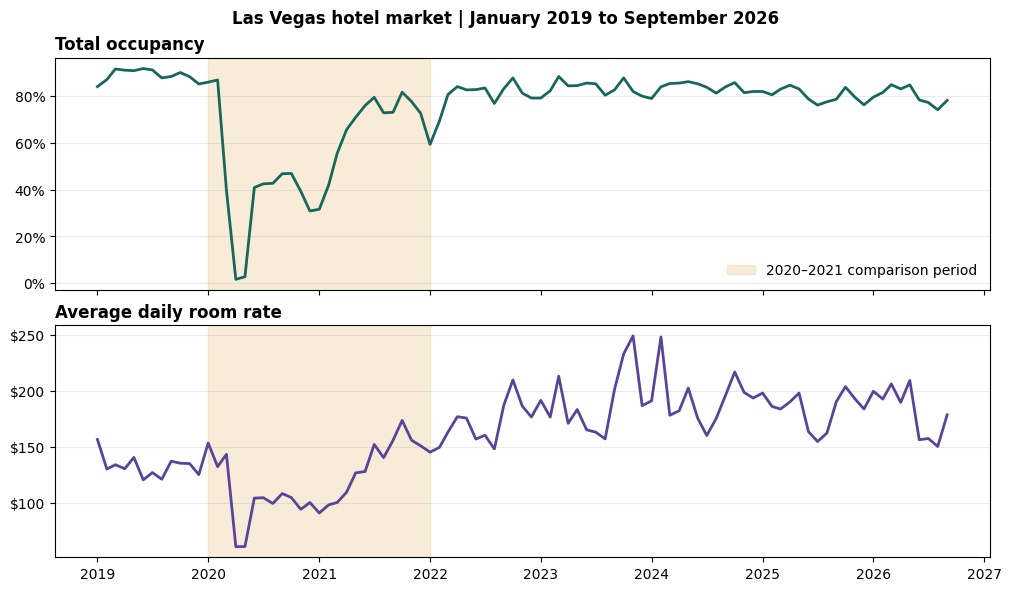

In [27]:
colors = {"occupancy": "#17675c", "adr": "#59449a"}
titles = {"occupancy": "Total occupancy", "adr": "Average daily room rate"}
formatters = {"occupancy": PercentFormatter(1), "adr": StrMethodFormatter("${x:,.0f}")}

fig, axes = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True, layout="constrained")
for ax, metric in zip(axes, hotel_monthly.columns):
    ax.plot(hotel_monthly.index, hotel_monthly[metric], color=colors[metric], linewidth=2)
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-01-01"),
               color="#e5b567", alpha=0.25, label="2020–2021 comparison period")
    ax.set_title(titles[metric], loc="left", fontweight="bold")
    ax.yaxis.set_major_formatter(formatters[metric])
    ax.grid(axis="y", alpha=0.25)
axes[0].legend(loc="lower right", frameon=False)
fig.suptitle("Las Vegas hotel market | January 2019 to September 2026", fontweight="bold")
plt.show()

## Seasonal Profiles

The median for each calendar month uses the same four complete years, 2022–2025. Individual years show how much each month's result can vary around that median.

We use 2022–2025 to show recent seasonal patterns across four complete years. The earlier years cover the pre-pandemic market (2019) and the pandemic disruption and recovery (2020–2021). The 2026 data run through September.

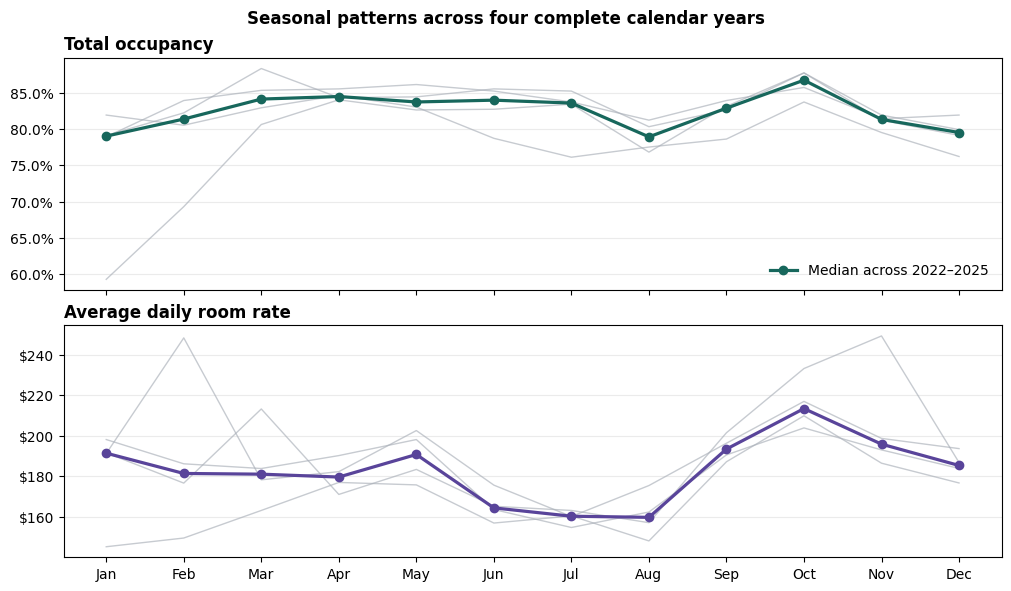

Total occupancy: highest median in October (86.7%)
Total occupancy: lowest median in August (78.9%)
Average daily room rate: highest median in October ($213.44)
Average daily room rate: lowest median in August ($159.74)


In [28]:
seasonal_sample = hotel_monthly.loc["2022":"2025"]
seasonal_medians = seasonal_sample.groupby(seasonal_sample.index.month).median()

fig, axes = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True, layout="constrained")
for ax, metric in zip(axes, hotel_monthly.columns):
    by_year = seasonal_sample[metric].groupby(seasonal_sample.index.year)
    for year, values in by_year:
        ax.plot(values.index.month, values, color="#a9afb8", alpha=0.65, linewidth=1)
    ax.plot(seasonal_medians.index, seasonal_medians[metric],
            color=colors[metric], marker="o", linewidth=2.3, label="Median across 2022–2025")
    ax.set_title(titles[metric], loc="left", fontweight="bold")
    ax.yaxis.set_major_formatter(formatters[metric])
    ax.grid(axis="y", alpha=0.25)
axes[0].legend(loc="best", frameon=False)
axes[1].set_xticks(range(1, 13), pd.date_range("2025-01-01", periods=12, freq="MS").strftime("%b"))
fig.suptitle("Seasonal patterns across four complete calendar years", fontweight="bold")
plt.show()

for metric in hotel_monthly.columns:
    medians = seasonal_medians[metric]
    for description, month in [("highest", medians.idxmax()), ("lowest", medians.idxmin())]:
        value = medians.loc[month]
        formatted = f"{value:.1%}" if metric == "occupancy" else f"${value:,.2f}"
        print(f"{titles[metric]}: {description} median in "
              f"{pd.Timestamp(2025, int(month), 1):%B} ({formatted})")

Across 2022–2025, August had the lowest median occupancy and ADR, while October had the highest median for both. This late-summer dip and fall rebound provide a seasonal benchmark for Las Vegas hotel planning.

## Seasonality by Year

The heatmaps show where patterns recur and where particular years depart from them. Gray cells represent months outside the observed period.

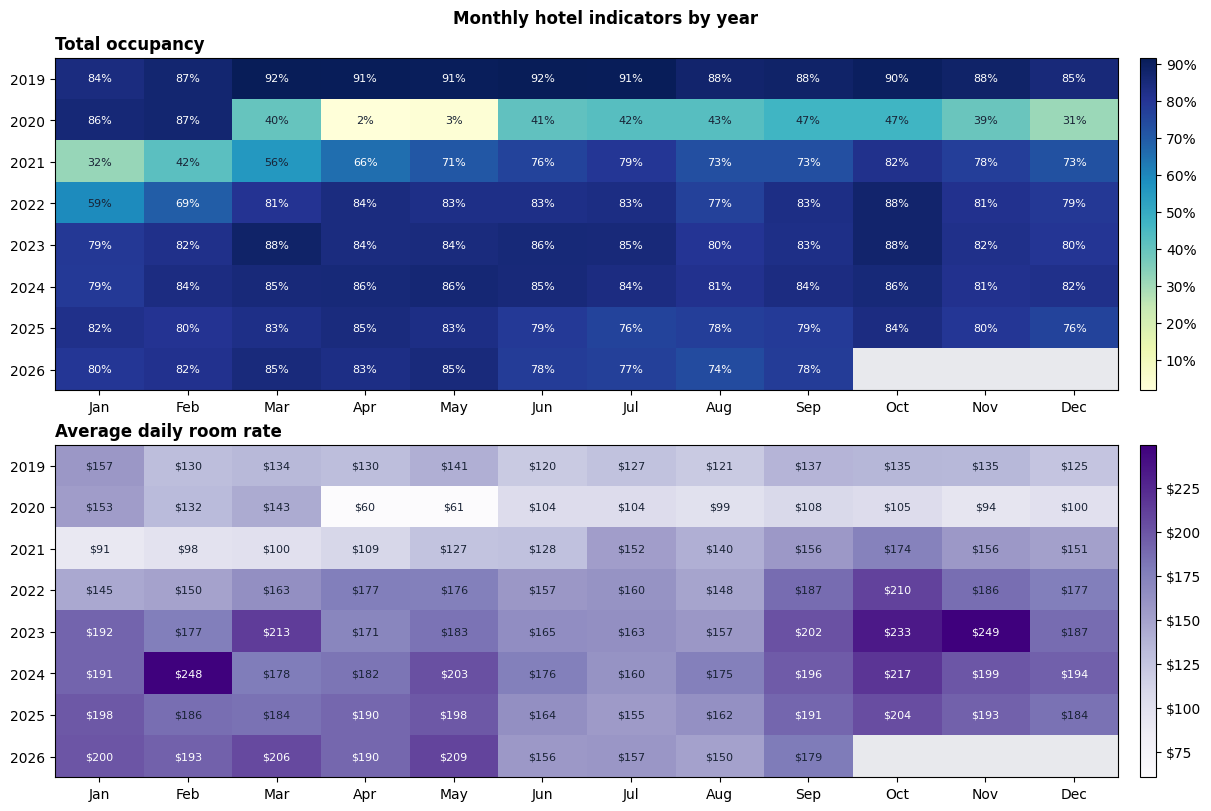

In [29]:
import calendar

month_numbers = range(1, 13)
month_labels = list(calendar.month_abbr)[1:]
calendar_view = hotel_monthly.assign(
    year=hotel_monthly.index.year,
    calendar_month=hotel_monthly.index.month,
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), layout="constrained")
for ax, metric, palette in zip(axes, hotel_monthly.columns, ["YlGnBu", "Purples"]):
    grid = calendar_view.pivot(index="year", columns="calendar_month", values=metric)
    grid = grid.reindex(columns=month_numbers)
    cmap = plt.get_cmap(palette).copy()
    cmap.set_bad("#e8e9ed")
    image = ax.imshow(grid, aspect="auto", cmap=cmap)
    for row, values in enumerate(grid.to_numpy()):
        for column, value in enumerate(values):
            if pd.notna(value):
                label = f"{value:.0%}" if metric == "occupancy" else f"${value:.0f}"
                color = "white" if image.norm(value) > 0.68 else "#182235"
                ax.text(column, row, label, ha="center", va="center", color=color, fontsize=8)
    ax.set_xticks(range(12), month_labels)
    ax.set_yticks(range(len(grid)), grid.index)
    ax.set_title(titles[metric], loc="left", fontweight="bold")
    fig.colorbar(image, ax=ax, format=formatters[metric], pad=0.02)
fig.suptitle("Monthly hotel indicators by year", fontweight="bold")
plt.show()

October had higher occupancy and ADR than August in each year from 2022 through 2025, reinforcing the late-summer dip and fall rebound seen in the seasonal profiles.

## Relationship Between Occupancy and ADR

We examine whether months with higher occupancy also tend to have higher average daily rates (ADR). Each point represents one month from 2022 through 2025, the same four complete years used in the seasonal profiles. Spearman’s rank correlation measures how consistently higher occupancy is associated with higher ADR. Shared seasonal patterns can contribute to this association.

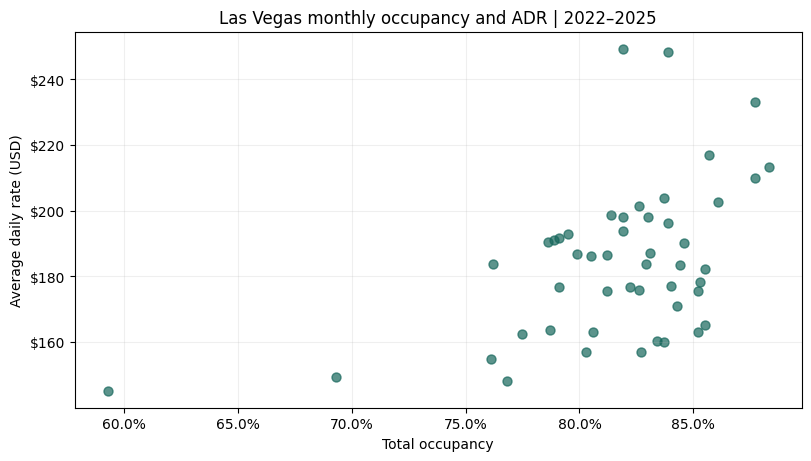

Spearman's rank correlation: 0.40 (n = 48 months)


In [30]:
occupancy_adr = hotel_monthly.loc["2022":"2025", ["occupancy", "adr"]]
spearman_rho = occupancy_adr["occupancy"].corr(
    occupancy_adr["adr"], method="spearman"
)

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.scatter(
    occupancy_adr["occupancy"],
    occupancy_adr["adr"],
    color="#17675c",
    alpha=0.7,
    s=42,
)

ax.set_title("Las Vegas monthly occupancy and ADR | 2022–2025")
ax.set_xlabel("Total occupancy")
ax.set_ylabel("Average daily rate (USD)")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(alpha=0.2)

plt.show()
print(f"Spearman's rank correlation: {spearman_rho:.2f} (n = {len(occupancy_adr)} months)")

Across the 48 months from 2022 through 2025, occupancy and ADR showed a positive rank correlation (Spearman’s ρ = 0.40). Months with higher occupancy tended to have higher room rates, though rates varied substantially at similar occupancy levels.

## Recent Year-over-Year Movement

Comparing each month with the same month a year earlier helps distinguish recent movements from recurring seasonality. Occupancy differences are in percentage points, and ADR changes are in relative percentages. The latest complete year-over-year comparison in this snapshot is September 2026.

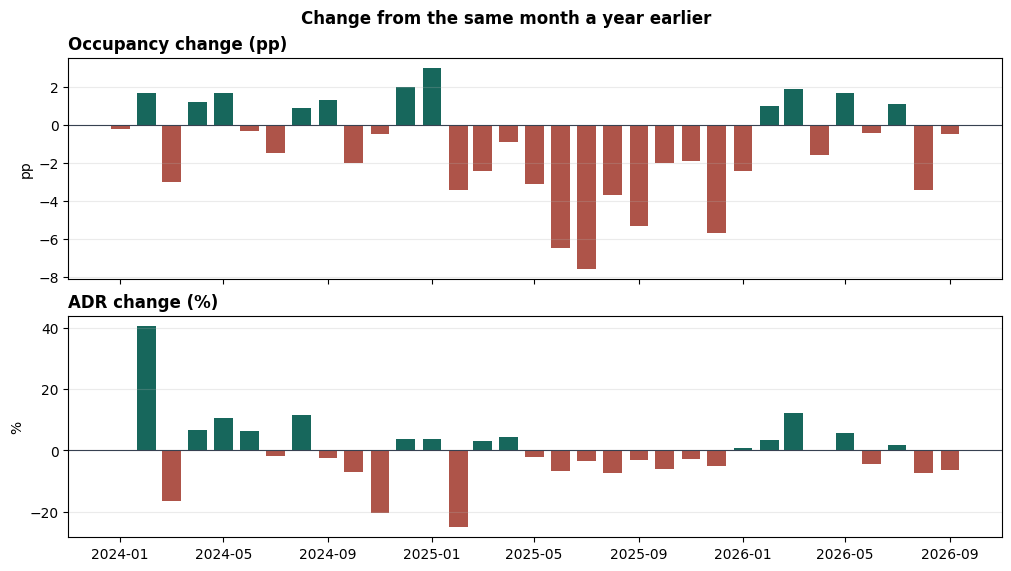

,Occupancy change (pp),ADR change (%)
month,,
2026-07-01,1.1,1.76
2026-08-01,-3.4,-7.42
2026-09-01,-0.5,-6.26


In [31]:
yoy = pd.DataFrame({
    "Occupancy change (pp)": hotel_monthly["occupancy"].diff(12).mul(100),
    "ADR change (%)": hotel_monthly["adr"].pct_change(12).mul(100),
}).loc["2024":]

fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, layout="constrained")
for ax, column in zip(axes, yoy.columns):
    values = yoy[column]
    bar_colors = values.map(lambda value: "#17675c" if value >= 0 else "#ae5449")
    ax.bar(values.index, values, width=22, color=bar_colors)
    ax.axhline(0, color="#374151", linewidth=0.8)
    ax.set_ylabel("pp" if column.startswith("Occupancy") else "%")
    ax.set_title(column, loc="left", fontweight="bold")
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Change from the same month a year earlier", fontweight="bold")
plt.show()
display(yoy.tail(3).round(2))

Occupancy was below the prior-year level in every month from February through December 2025, with the largest decline in July (7.6 percentage points). The recovery was uneven in 2026, and both occupancy and ADR were below their prior-year levels in August and September.

## Weekend and Midweek Demand

Monthly total occupancy summarizes market demand, which can hide differences across the week. This comparison uses reported weekend and midweek values for 2022–2025 to illustrate why a hotel manager would consult more granular data before setting individual shifts.

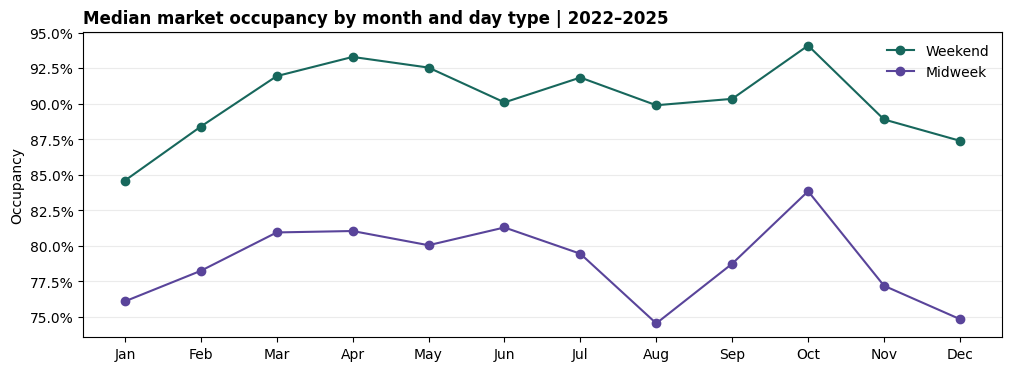

Weekend minus midweek across the monthly profiles: 8.5 to 15.3 percentage points.


In [32]:
weekday_patterns = (
    cleaned_market_indicators.loc["2022":"2025", ["Weekend Occupancy", "Midweek Occupancy"]]
    .apply(pd.to_numeric, errors="raise")
)
weekday_profiles = weekday_patterns.groupby(weekday_patterns.index.month).median()

fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
ax.plot(weekday_profiles.index, weekday_profiles["Weekend Occupancy"],
        marker="o", color="#17675c", label="Weekend")
ax.plot(weekday_profiles.index, weekday_profiles["Midweek Occupancy"],
        marker="o", color="#59449a", label="Midweek")
ax.set_xticks(list(month_numbers), month_labels)
ax.set_ylabel("Occupancy")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Median market occupancy by month and day type | 2022–2025",
             loc="left", fontweight="bold")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
plt.show()

gap = weekday_profiles["Weekend Occupancy"] - weekday_profiles["Midweek Occupancy"]
print(f"Weekend minus midweek across the monthly profiles: "
      f"{gap.min() * 100:.1f} to {gap.max() * 100:.1f} percentage points.")

Weekend occupancy exceeded midweek occupancy in every calendar month. The gap was widest in August at 15.3 percentage points, with median occupancy near 90% on weekends and 75% midweek. Both groups peaked in October. The August gap suggests that hotels could evaluate midweek promotions separately from weekend pricing.

## Room Supply and Usage

Room inventory is a count of available rooms. Occupied room nights count rooms sold across all nights in a month. Dividing by the number of days makes room-night volumes comparable across months. The indexed series below compare their growth since January 2022. The published occupancy series remains the market benchmark.

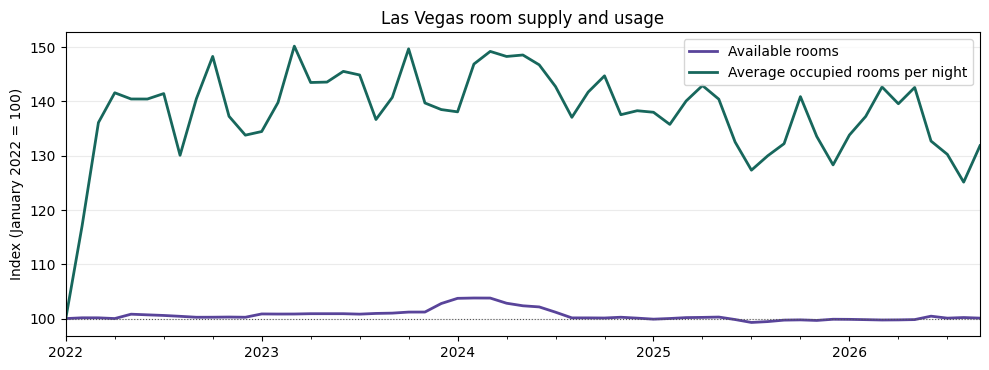

In [33]:
supply_usage = cleaned_market_indicators.loc["2022":, [
    "Available Room Inventory", "Total Room Nights Occupied"
]].apply(pd.to_numeric, errors="raise")
supply_usage["Total Room Nights Occupied"] = (
    supply_usage["Total Room Nights Occupied"] / supply_usage.index.days_in_month
)
supply_usage = supply_usage.rename(columns={
    "Available Room Inventory": "Available rooms",
    "Total Room Nights Occupied": "Average occupied rooms per night",
})
supply_index = supply_usage.div(supply_usage.iloc[0]).mul(100)
ax = supply_index.plot(figsize=(10, 3.8), color=["#59449a", "#17675c"], linewidth=2)
ax.axhline(100, color="#555555", linewidth=0.8, linestyle=":")
ax.set(title="Las Vegas room supply and usage", ylabel="Index (January 2022 = 100)", xlabel="")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Room inventory remained relatively stable, while the average number of occupied rooms per night varied considerably. This suggests that changes in room usage were more important to occupancy fluctuations over this period than changes in room inventory.

## Tourism Activity and Hotel Performance

Visitor volume, convention attendance, and airport passenger movements provide different views of tourism activity. We compare their monthly year-over-year changes with changes in occupancy and ADR. Comparing the same month across years reduces recurring seasonal differences. Spearman correlations summarize how consistently the changes move together. Airport movements include enplaned and deplaned passengers and are a proxy for travel activity.

Matched monthly comparisons: 45


,Occupancy (pp),ADR (%)
Visitor Volume,0.85,0.69
Convention Attendance,0.50,0.50
Total En/Deplaned Passengers,0.61,0.63


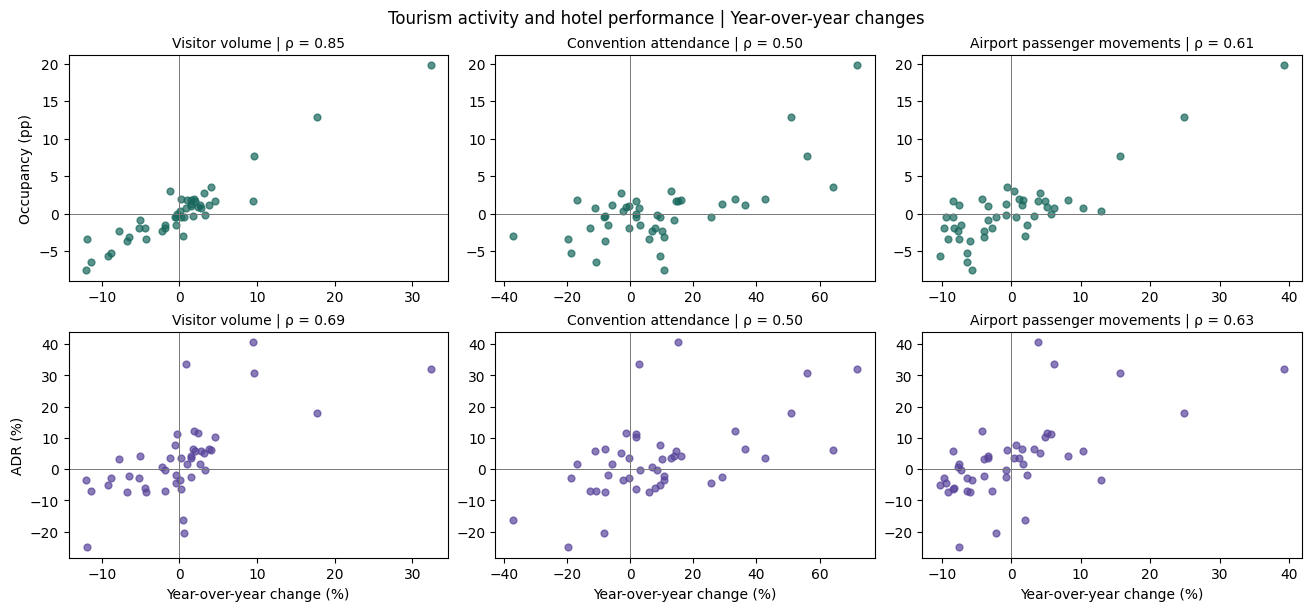

In [34]:
activity_columns = ["Visitor Volume", "Convention Attendance", "Total En/Deplaned Passengers"]
activity = cleaned_market_indicators.loc["2022":, activity_columns].apply(
    pd.to_numeric, errors="raise"
)
activity_change = activity.pct_change(12, fill_method=None).mul(100)
outcome_change = pd.DataFrame({
    "Occupancy (pp)": hotel_monthly["occupancy"].diff(12).mul(100),
    "ADR (%)": hotel_monthly["adr"].pct_change(12, fill_method=None).mul(100),
})
activity_comparison = activity_change.join(outcome_change).dropna()
association = activity_comparison.corr(method="spearman").loc[
    activity_columns, outcome_change.columns
]
print(f"Matched monthly comparisons: {len(activity_comparison)}")
display(association.round(2))

activity_names = ["Visitor volume", "Convention attendance", "Airport passenger movements"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), layout="constrained")
for column, (indicator, label) in enumerate(zip(activity_columns, activity_names)):
    for row, outcome in enumerate(outcome_change.columns):
        ax = axes[row, column]
        ax.scatter(activity_comparison[indicator], activity_comparison[outcome],
                   color=["#17675c", "#59449a"][row], alpha=0.7, s=24)
        ax.axhline(0, color="#777777", linewidth=0.7)
        ax.axvline(0, color="#777777", linewidth=0.7)
        ax.set_title(f"{label} | ρ = {association.loc[indicator, outcome]:.2f}",
                     fontsize=10)
        if column == 0:
            ax.set_ylabel(outcome)
        if row == 1:
            ax.set_xlabel("Year-over-year change (%)")
fig.suptitle("Tourism activity and hotel performance | Year-over-year changes")
plt.show()

Across 45 monthly year-over-year comparisons, visitor volume had the strongest rank correlation with changes in both occupancy (ρ = 0.85) and ADR (ρ = 0.69). Airport passenger movements ranked second for both outcomes (ρ = 0.61 for occupancy and 0.63 for ADR). Convention attendance was also positively associated with both outcomes (ρ = 0.50 for each), although hotel performance did not always improve when convention attendance rose.

These correlations describe how the indicators moved together in the same month. To determine whether these indicators improve forecasts, we would need to test them using only information available at the time each forecast is made.

## Strip and Downtown Room Economics

Revenue per available room (RevPAR) combines room prices and room usage. It is approximately ADR multiplied by occupancy when both metrics describe the same segment and period. Comparing the Strip and Downtown alongside the market benchmark shows how segment results can differ from the market forecast. The charts use medians across complete 2022–2025 calendar years.

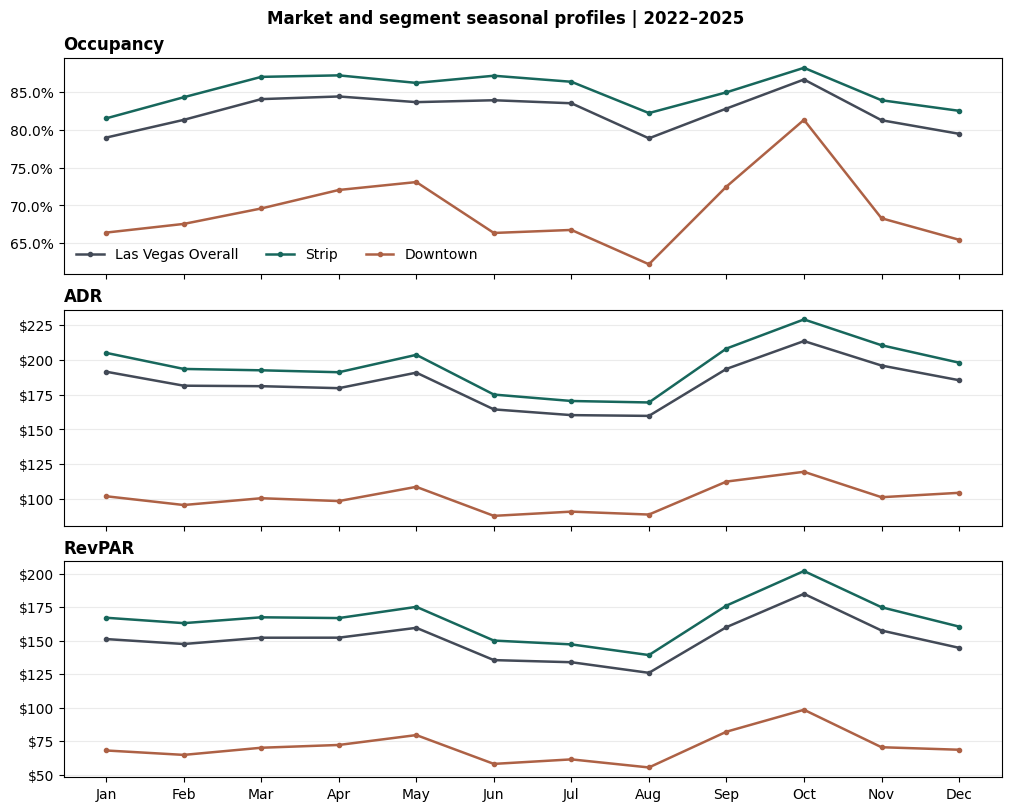

In [35]:
segment_metrics = {
    "Occupancy": ["Total Occupancy", "Strip Occupancy", "Downtown Occupancy"],
    "ADR": ["Average Daily Room Rate (ADR)", "Strip ADR", "Downtown ADR"],
    "RevPAR": ["Revenue Per Available Room (RevPAR)", "Strip RevPAR", "Downtown RevPAR"],
}
segment_names = ["Las Vegas Overall", "Strip", "Downtown"]
segment_colors = ["#434a57", "#17675c", "#ad6145"]
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")

for ax, (metric, columns) in zip(axes, segment_metrics.items()):
    observed = cleaned_market_indicators.loc["2022":"2025", columns].apply(
        pd.to_numeric, errors="raise"
    )
    profiles = observed.groupby(observed.index.month).median()
    for column, segment, color in zip(columns, segment_names, segment_colors):
        ax.plot(profiles.index, profiles[column], color=color, marker="o",
                markersize=3, linewidth=1.8, label=segment)
    ax.set_title(metric, loc="left", fontweight="bold")
    ax.yaxis.set_major_formatter(formatters["occupancy" if metric == "Occupancy" else "adr"])
    ax.grid(axis="y", alpha=0.25)
axes[0].legend(frameon=False, ncol=3)
axes[-1].set_xticks(list(month_numbers), month_labels)
fig.suptitle("Market and segment seasonal profiles | 2022–2025", fontweight="bold")
plt.show()

Both the Strip and Downtown reached their highest median occupancy, ADR, and RevPAR in October. Downtown occupancy rose from about 62% in August to 81% in October, narrowing the occupancy gap with the Strip. Even in October, the Strip’s median ADR was nearly twice Downtown’s, and its median RevPAR was about $202 versus \$98. The two areas share a seasonal peak, but their room rates and revenue per available room differ substantially.

## What Drives the Strip–Downtown RevPAR Gap?

We compare the Strip and Downtown month by month from January 2022 through September 2026. To distinguish the roles of pricing and occupancy, we decompose the gap in implied RevPAR (ADR × occupancy). The rate contribution uses the average occupancy of the two segments. The occupancy contribution uses their average ADR. The two contributions sum exactly to the implied gap, which can differ slightly from the reported gap because of rounding.

,Mean USD per available room
Rate contribution,73.46
Occupancy contribution,23.61
Implied RevPAR gap,97.07
Reported RevPAR gap,97.07


/tmp/ipykernel_7346/828732352.py:32: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(reported_gap.index, reported_gap, label="Reported gap", color="#222222",


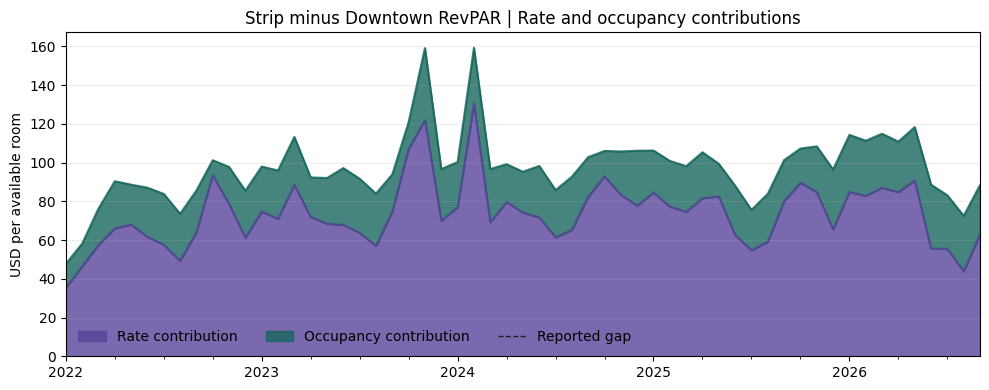

Rate share of the mean implied gap: 75.7%


In [36]:
segment_gap = cleaned_market_indicators.loc["2022":, [
    "Strip Occupancy", "Downtown Occupancy", "Strip ADR", "Downtown ADR",
    "Strip RevPAR", "Downtown RevPAR",
]].apply(pd.to_numeric, errors="raise")

rate_component = (segment_gap["Strip ADR"] - segment_gap["Downtown ADR"]) * (
    (segment_gap["Strip Occupancy"] + segment_gap["Downtown Occupancy"]) / 2
)
occupancy_component = (
    segment_gap["Strip Occupancy"] - segment_gap["Downtown Occupancy"]
) * ((segment_gap["Strip ADR"] + segment_gap["Downtown ADR"]) / 2)
reported_gap = segment_gap["Strip RevPAR"] - segment_gap["Downtown RevPAR"]
components = pd.DataFrame({
    "Rate contribution": rate_component,
    "Occupancy contribution": occupancy_component,
})
assert (
    components.sum(axis=1).sub(
        segment_gap["Strip ADR"] * segment_gap["Strip Occupancy"]
        - segment_gap["Downtown ADR"] * segment_gap["Downtown Occupancy"]
    ).abs().max() < 1e-9
)

summary = components.mean().to_frame("Mean USD per available room")
summary.loc["Implied RevPAR gap"] = components.sum(axis=1).mean()
summary.loc["Reported RevPAR gap"] = reported_gap.mean()
display(summary.round(2))

ax = components.plot.area(
    stacked=True, figsize=(10, 4), color=["#59449a", "#17675c"], alpha=0.8
)
ax.plot(reported_gap.index, reported_gap, label="Reported gap", color="#222222",
        linewidth=1, linestyle="--")
ax.set(title="Strip minus Downtown RevPAR | Rate and occupancy contributions",
       ylabel="USD per available room", xlabel="")
ax.legend(frameon=False, ncol=3)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print(f"Rate share of the mean implied gap: "
      f"{rate_component.mean() / components.sum(axis=1).mean():.1%}")

From January 2022 through September 2026, the Strip’s implied RevPAR exceeded Downtown’s by an average of \$97.07 per available room. The ADR difference accounted for \$73.46 (75.7%) of the gap, and the occupancy difference accounted for $23.61.

Differences in room rates therefore contributed more to the observed RevPAR gap than differences in occupancy.

## When Higher Occupancy Coincides with Lower RevPAR

A hotel can fill a larger share of its rooms while earning less room revenue per available room if the sold-room rate falls enough. We compare the market with the same month one year earlier from 2023 onward and flag months where occupancy rose while reported RevPAR fell. RevPAR measures room revenue per available room. Profit would also require operating costs.

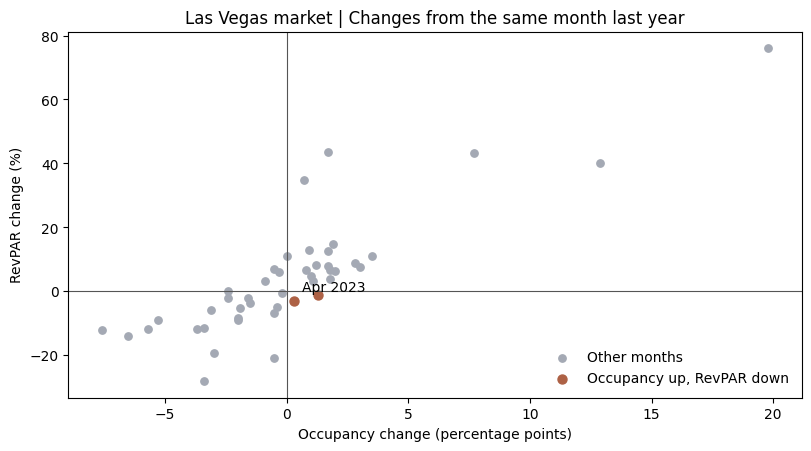

Occupancy rose while RevPAR fell in 2 of 45 months.


,Occupancy change (pp),ADR change (%),RevPAR change (%)
month,,,
2023-04-01,0.3,-3.35,-2.99
2024-09-01,1.3,-2.56,-1.03


,Occupancy (%),ADR (USD),RevPAR (USD)
month,,,
2022-04-01,84.0,176.97,148.65
2023-04-01,84.3,171.05,144.20


In [37]:
market_revenue = cleaned_market_indicators[[
    "Total Occupancy", "Average Daily Room Rate (ADR)",
    "Revenue Per Available Room (RevPAR)",
]].apply(pd.to_numeric, errors="raise")
market_revenue.columns = ["Occupancy", "ADR", "RevPAR"]

revenue_change = pd.DataFrame({
    "Occupancy change (pp)": market_revenue["Occupancy"].diff(12).mul(100),
    "ADR change (%)": market_revenue["ADR"].pct_change(12, fill_method=None).mul(100),
    "RevPAR change (%)": market_revenue["RevPAR"].pct_change(12, fill_method=None).mul(100),
}).loc["2023":]
divergent = revenue_change.loc[
    revenue_change["Occupancy change (pp)"].gt(0)
    & revenue_change["RevPAR change (%)"].lt(0)
].sort_values("RevPAR change (%)")

fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
ax.scatter(revenue_change["Occupancy change (pp)"], revenue_change["RevPAR change (%)"],
           color="#a4a9b4", s=28, label="Other months")
ax.scatter(divergent["Occupancy change (pp)"], divergent["RevPAR change (%)"],
           color="#ad6145", s=42, label="Occupancy up, RevPAR down")
ax.axhline(0, color="#555555", linewidth=0.8)
ax.axvline(0, color="#555555", linewidth=0.8)
if not divergent.empty:
    example = divergent.iloc[0]
    ax.annotate(f"{example.name:%b %Y}",
                (example["Occupancy change (pp)"], example["RevPAR change (%)"]),
                xytext=(6, 7), textcoords="offset points")
ax.set(title="Las Vegas market | Changes from the same month last year",
       xlabel="Occupancy change (percentage points)", ylabel="RevPAR change (%)")
ax.legend(frameon=False)
plt.show()

print(f"Occupancy rose while RevPAR fell in {len(divergent)} of {len(revenue_change)} months.")
display(divergent.head(5).round(2))
if not divergent.empty:
    example_month = divergent.index[0]
    display(market_revenue.loc[[example_month - pd.DateOffset(years=1), example_month]]
            .assign(Occupancy=lambda table: table["Occupancy"].mul(100))
            .rename(columns={"Occupancy": "Occupancy (%)", "ADR": "ADR (USD)",
                             "RevPAR": "RevPAR (USD)"}).round(2))

Occupancy rose while RevPAR fell in 2 of 45 year-over-year comparisons. In April 2023, occupancy rose by 0.3 percentage points, while ADR fell by 3.35% and RevPAR fell by 2.99%. In September 2024, a larger occupancy gain of 1.3 percentage points still coincided with a 1.03% decline in RevPAR as ADR fell by 2.56%. These two cases illustrate why occupancy and room rates should be evaluated together.

## Interpretation and Forecasting Implications

- **Seasonality provides a planning benchmark.** October had the highest median occupancy (86.7%) and ADR (\$213.44) in 2022–2025. August had the lowest median for both (78.9% and \$159.74). A useful forecast should improve on the natural benchmark of using the same month last year.
- **Recent conditions still vary from year to year.** In September 2026, occupancy was 0.5 percentage points below September 2025, while ADR was 6.3% lower. The forecast should allow expected pricing and occupancy to move by different amounts.
- **The pandemic warrants sensitivity analysis.** April 2020 occupancy reached 1.7% and ADR was \$60.50. Any training-window or shock-treatment comparison should use the same real observations for evaluation. The inputs in this notebook retain the reported observations.
- **Monthly forecasts support planning at the market level.** Weekend occupancy exceeded midweek occupancy across the seasonal profiles. Staff scheduling for a given property requires booking or occupancy information at a finer frequency.
- **Revised reporting affects historical evaluation.** The archived workbooks include retrospective revisions. Backtesting against this snapshot evaluates accuracy on revised observations. Recreating what was known on each historical forecast date would require historical release vintages.
- **The Strip's room-rate premium explains most of its implied RevPAR gap.** From January 2022 through September 2026, the mean implied gap was \$97.07 per available room. The rate component accounted for \$73.46 (75.7%), and occupancy accounted for \$23.61.
- **Higher occupancy can coincide with lower room revenue per available room.** This happened in two of 45 year-over-year comparisons. In April 2023, occupancy rose from 84.0% to 84.3%, while ADR fell from \$176.97 to \$171.05 and reported RevPAR fell from \$148.65 to \$144.20.
- **Tourism indicators add context.** Year-over-year visitor volume changes had Spearman correlations of 0.85 with occupancy changes and 0.69 with ADR changes. Airport passenger changes had correlations of 0.61 and 0.63, respectively. Convention attendance changes had correlations of 0.50 with both. These are descriptive associations.